In [5]:
import numpy as np
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([35, 42, 50, 58, 65])

model = LinearRegression()
model.fit(X, y)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

prediction = model.predict([[6]])
print("Predicted marks:", prediction[0])

Slope: 7.599999999999999
Intercept: 27.200000000000003
Predicted marks: 72.8


In [6]:
m = 7
c = 30

x = 6
y = m*x + c

print(y)

72


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [8]:
from sklearn.datasets import load_boston

ImportError: 
`load_boston` has been removed from scikit-learn since version 1.2.

The Boston housing prices dataset has an ethical problem: as
investigated in [1], the authors of this dataset engineered a
non-invertible variable "B" assuming that racial self-segregation had a
positive impact on house prices [2]. Furthermore the goal of the
research that led to the creation of this dataset was to study the
impact of air quality but it did not give adequate demonstration of the
validity of this assumption.

The scikit-learn maintainers therefore strongly discourage the use of
this dataset unless the purpose of the code is to study and educate
about ethical issues in data science and machine learning.

In this special case, you can fetch the dataset from the original
source::

    import pandas as pd
    import numpy as np

    data_url = "http://lib.stat.cmu.edu/datasets/boston"
    raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
    data = np.hstack([raw_df.values[:

In [ ]:
import pandas as pd
import numpy as np

# This bypasses sklearn and pulls the raw text file from Carnegie Mellon University
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)

# This messy math slices the text file back into proper tables
X = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
y = raw_df.values[1::2, 2]

In [ ]:
load_boston()

In [ ]:
import pandas as pd
import numpy as np

def load_boston():
    """Custom replica of the deprecated sklearn load_boston function."""
    data_url = "http://lib.stat.cmu.edu/datasets/boston"
    raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
    
    # Reconstruct features (X) and target (y) columns
    X = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
    y = raw_df.values[1::2, 2]
    
    # Original Boston dataset feature names
    feature_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 
                     'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']
                     
    # Pack it into a custom object to mimic how sklearn packages datasets
    class BostonData:
        def __init__(self, data, target, feature_names):
            self.data = data
            self.target = target
            self.feature_names = feature_names
            # Also provide a pandas DataFrame version if your tutorial uses it
            self.frame = pd.DataFrame(data, columns=feature_names)
            self.frame['MEDV'] = target

    return BostonData(X, y, feature_names)

# --- NOW YOU CAN USE IT EXACTLY LIKE THE TUTORIAL ---
boston = load_boston()
X = boston.data
y = boston.target

print("Success! Your custom load_boston() function worked.")
print(f"Features matrix shape: {X.shape} (506 rows, 13 features)")

In [ ]:
df=load_boston()

In [ ]:
pd.DataFrame(df.data)

In [ ]:
z=y+10
z

In [43]:
df= pd.read_csv("D:\ML\PYTHON\salaries.csv")
df

,Experience (Years),Salary (?)
0,1,25000
1,2,30000
2,3,35000
3,4,40000
4,5,45000
5,6,50000
6,7,55000
7,8,60000
8,9,65000
9,10,70000


In [ ]:
df.head()

In [44]:
x = df.iloc[:,:-1]
x[0:5]


,Experience (Years)
0,1
1,2
2,3
3,4
4,5


In [45]:
y = df.iloc[:,-1].values
y[0:5]


array([25000, 30000, 35000, 40000, 45000])

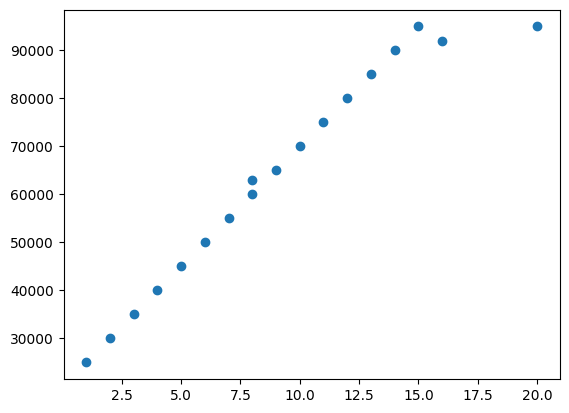

In [46]:
plt.scatter(x,y)


In [47]:
from sklearn.model_selection import train_test_split
x_train,  x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=0)
y_test.shape
                                                     

(4,)

In [48]:
from sklearn.linear_model import LinearRegression

# 1. Reset 'model' so it's a Linear Regression algorithm instead of a DataFrame
model = LinearRegression()

# 2. Now run the fit command again (it will work perfectly this time!)
model.fit(x_train, y_train)

print("Success! The model has been trained.")

Success! The model has been trained.


In [49]:
model.fit(x_train ,  y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [56]:
model.predict([[7], [5] , [20]])A

C:\Users\LENOVO\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([ 54919.92914083,  46480.95659876, 109773.2506643 ])

In [51]:
y_p=model.predict(x_test)
y_p

array([33822.49778565, 54919.92914083, 63358.90168291, 71797.87422498])

In [57]:
error = y_p - y_test
error

array([ 3822.49778565,   -80.07085917, -1641.09831709, -3202.12577502])

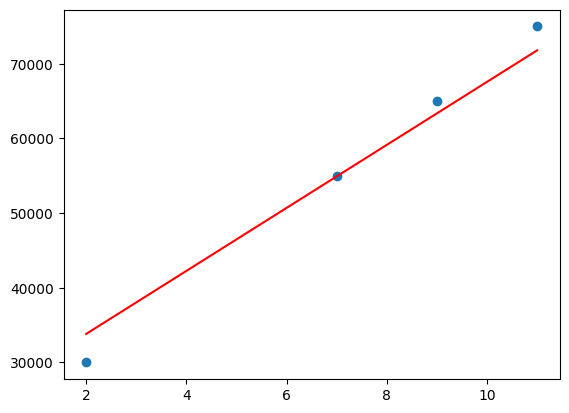

In [53]:
plt.scatter(x_test, y_test)
plt.plot(x_test, y_p , color='red')


In [54]:
from sklearn.metrics import r2_score
r2= r2_score(y_test , y_p)
r2


0.975361149649853

In [58]:
import pandas as pd

# Create a table comparing true answers vs guesses
error_table = pd.DataFrame({
    'Actual Salary (y_test)': y_test,
    'Predicted Salary (y_p)': y_p
})

# Calculate the exact difference for every row
error_table['Exact Error'] = error_table['Predicted Salary (y_p)'] - error_table['Actual Salary (y_test)']

print(error_table)

   Actual Salary (y_test)  Predicted Salary (y_p)  Exact Error
0                   30000            33822.497786  3822.497786
1                   55000            54919.929141   -80.070859
2                   65000            63358.901683 -1641.098317
3                   75000            71797.874225 -3202.125775


In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Load your dataset
df = pd.read_csv("D:\ML\PYTHON\salaries.csv")

# 2. Map text qualifications to numeric ranks
education_map = {
    'High School': 1,
    'Bachelors': 2,
    'Masters': 3,
    'PhD': 4
}
df['qualifications'] = df['qualifications'].map(education_map)

# 3. Separate your Features (X) and Target (y)
X = df[['Experiences', 'qualifications']]
y = df['Salary']

# 4. Split and Train exactly as before
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
model = LinearRegression()
model.fit(X_train, y_train)

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values